<a href="https://colab.research.google.com/github/RishabhKash/rag/blob/main/rag_implementation_haystack.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# pip install nvidia-haystack serperdev-haystack gradio

In [3]:
import warnings
warnings.filterwarnings('ignore')

from google.colab import userdata
from haystack.utils import Secret
NVIDIA_API_KEY = Secret.from_token(userdata.get("nvidia_key"))
SERPER_API_KEY = Secret.from_token(userdata.get("serper"))

In [4]:
from haystack_integrations.components.embedders.nvidia import NvidiaDocumentEmbedder

embedder = NvidiaDocumentEmbedder(model="nvidia/nemotron-3-embed-1b",)
embedder

Inputs:
  - documents: list[Document]
Outputs:
  - documents: list[Document]
  - meta: dict[str, Any]

In [5]:
from haystack.dataclasses import Document
from haystack_integrations.components.embedders.nvidia import NvidiaDocumentEmbedder

# Re-initialize the embedder using Secret.from_token to prevent the AttributeError
embedder = NvidiaDocumentEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)

documents = [
    Document(content="Newton formulated law of universal gravitation, which states that every mass attracts every other mass with a force proportional to their masses and inversely proportional to the square of the distance between them"),
    Document(content="Schrodinger cat is a thought experiment that illustrates quantum superposition, where a cat in a sealed box is considered both alive and dead until observed")
]

embedder.run(documents=documents)

Calculating embeddings: 100%|██████████| 1/1 [00:00<00:00,  1.56it/s]


{'documents': [Document(id=6546268855a0839b16d77658e452a732527d20c7f6e689f96ee824d93eda1a87, content: 'Newton formulated law of universal gravitation, which states that every mass attracts every other ma...', embedding: vector of size 2048),
  Document(id=80e71a97c45f319d9a4639be87b7add817a3975c414b3e1046e5c816a2c6bec2, content: 'Schrodinger cat is a thought experiment that illustrates quantum superposition, where a cat in a sea...', embedding: vector of size 2048)],
 'meta': {'usage': {'prompt_tokens': 70, 'total_tokens': 70}}}

In [6]:
from haystack.document_stores.in_memory import InMemoryDocumentStore

doc_store = InMemoryDocumentStore()

In [ ]:
# Pipeline to get the data ready for RAG

In [7]:
from haystack import Pipeline

from haystack.components.converters.txt import TextFileToDocument
from haystack.components.preprocessors.document_splitter import DocumentSplitter
from haystack_integrations.components.embedders.nvidia import NvidiaDocumentEmbedder
from haystack.components.writers import DocumentWriter

# initialize modules needed for loading, chunking, embedding and saving the data
converter = TextFileToDocument()
splitter = DocumentSplitter()
embedder = NvidiaDocumentEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
writer = DocumentWriter(document_store=doc_store)

data_pipeline = Pipeline()

# adding modules to a pipeline
data_pipeline.add_component("converter", converter)
data_pipeline.add_component("splitter", splitter)
data_pipeline.add_component("embedder", embedder)
data_pipeline.add_component("writer", writer)

# connect modules within a pipeline to form a sequence
data_pipeline.connect("converter", "splitter")
data_pipeline.connect("splitter", "embedder")
data_pipeline.connect("embedder", "writer")

🚅 Components
  - converter: TextFileToDocument
  - splitter: DocumentSplitter
  - embedder: NvidiaDocumentEmbedder
  - writer: DocumentWriter
🛤️ Connections
  - converter.documents -> splitter.documents (list[Document])
  - splitter.documents -> embedder.documents (list[Document])
  - embedder.documents -> writer.documents (list[Document])

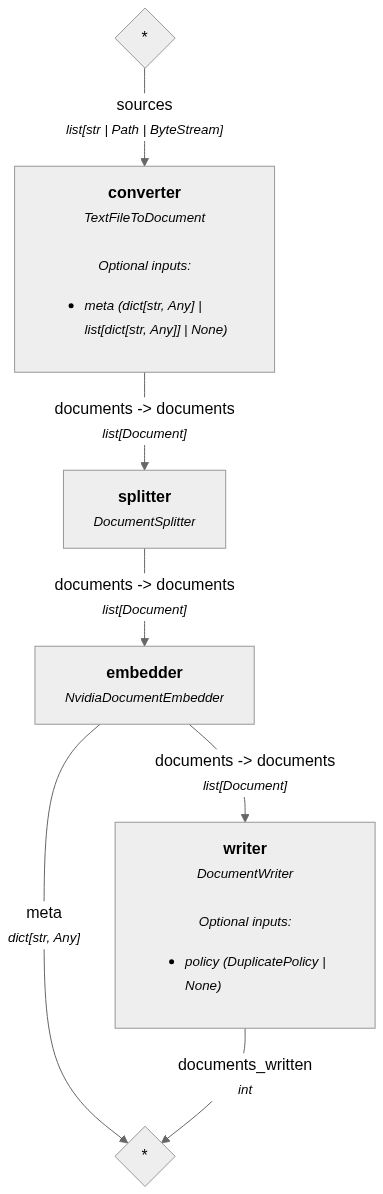

In [8]:
data_pipeline.show()

In [9]:
import os

# Create the directory if it does not exist
os.makedirs('data', exist_ok=True)

# Write a sample text file to index
sample_text = """
Newton's law of universal gravitation states that every particle in the universe attracts every other particle
with a force proportional to their masses and inversely proportional to the square of the distance between them
"""

with open('data/sample.txt', 'w', encoding='utf-8') as f:
    f.write(sample_text)

print("Sample file 'data/sample.txt' created successfully!")

Sample file 'data/sample.txt' created successfully!


In [10]:
# Run the data pipeline
data_pipeline.run({"converter": {"sources": ['data/sample.txt']}})

Calculating embeddings: 100%|██████████| 1/1 [00:00<00:00,  2.18it/s]


{'embedder': {'meta': {'usage': {'prompt_tokens': 44, 'total_tokens': 44}}},
 'writer': {'documents_written': 1}}

In [ ]:
# Document search pipeline without generation

In [11]:
from haystack_integrations.components.embedders.nvidia import NvidiaTextEmbedder
from haystack.components.retrievers.in_memory import InMemoryEmbeddingRetriever

query_embedder = NvidiaTextEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
retriever = InMemoryEmbeddingRetriever(document_store=doc_store)

document_search = Pipeline()

document_search.add_component("query_embedder", query_embedder)
document_search.add_component("retriever", retriever)

document_search.connect("query_embedder.embedding", "retriever.query_embedding")

🚅 Components
  - query_embedder: NvidiaTextEmbedder
  - retriever: InMemoryEmbeddingRetriever
🛤️ Connections
  - query_embedder.embedding -> retriever.query_embedding (list[float])

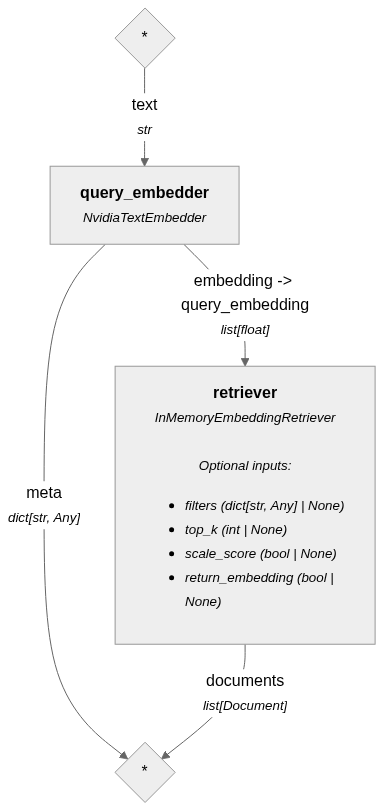

In [12]:
document_search.show()

In [13]:
question = "How does Netwon define gravity?"

document_search.run({"query_embedder": {"text": question}})

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 9,
    'total_tokens': 9}}},
 'retriever': {'documents': [Document(id=2fd8119a9ee123fb26afce62b8dda288edb90819f15b30a6c66f554973f28f6b, content: '
   Newton's law of universal gravitation states that every particle in the universe attracts every oth...', meta: {'file_path': 'sample.txt', 'source_id': 'd3b37ceabd3106aec76e199cb813b3326b767d02a195a44143bf777b7dac7a02', 'page_number': 1, 'split_id': 0, 'split_idx_start': 0}, score: 0.32637713310048955)]}}

In [ ]:
# Retrieval with generation

In [14]:
prompt = """
Answer the question based on provided context.
Context:
{% for doc in documents %}
  {{ doc.content }}
{% endfor %}
Question: {{ query }}
"""

In [15]:
from haystack.components.builders import PromptBuilder
from haystack_integrations.components.generators.nvidia import NvidiaChatGenerator

# modules needed for generation
query_embedder = NvidiaTextEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
retriever = InMemoryEmbeddingRetriever(document_store=doc_store)
prompt_builder = PromptBuilder(template=prompt)
generator = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning",api_key=NVIDIA_API_KEY)

rag = Pipeline()

# adding modules
rag.add_component("query_embedder", query_embedder)
rag.add_component("retriever", retriever)
rag.add_component("prompt_builder", prompt_builder)
rag.add_component("generator", generator)

# connect output to input
rag.connect("query_embedder.embedding", "retriever.query_embedding")
rag.connect("retriever.documents", "prompt_builder.documents")
rag.connect("prompt_builder", "generator")

🚅 Components
  - query_embedder: NvidiaTextEmbedder
  - retriever: InMemoryEmbeddingRetriever
  - prompt_builder: PromptBuilder
  - generator: NvidiaChatGenerator
🛤️ Connections
  - query_embedder.embedding -> retriever.query_embedding (list[float])
  - retriever.documents -> prompt_builder.documents (list[Document])
  - prompt_builder.prompt -> generator.messages (str)

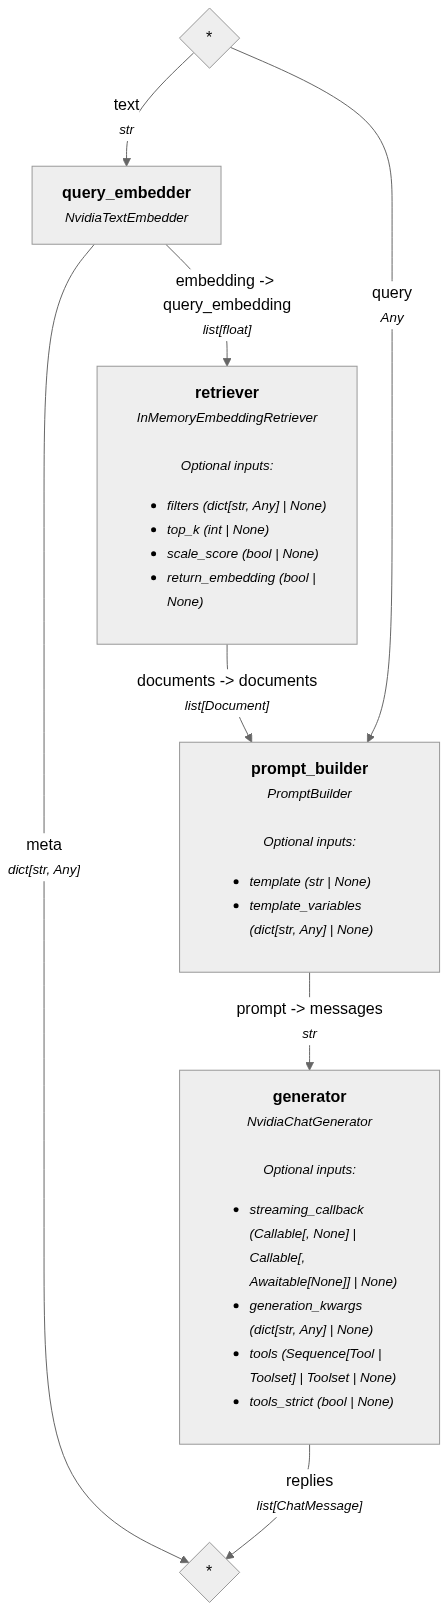

In [16]:
rag.show()

In [18]:
rag.run(
    {
        "query_embedder": {"text": question},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": question}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 9,
    'total_tokens': 9}}},
 'generator': {'replies': [ChatMessage(_role=<ChatRole.ASSISTANT: 'assistant'>, _content=[TextContent(text='Newton defines gravity as the universal attractive force between any two particles: the force is directly proportional to the product of their masses and inversely proportional to the square of the distance separating them.')], _name=None, _meta={'model': 'nvidia/nemotron-3-nano-omni-30b-a3b-reasoning', 'index': 0, 'finish_reason': 'stop', 'usage': {'completion_tokens': 139, 'prompt_tokens': 76, 'total_tokens': 215, 'completion_tokens_details': None, 'prompt_tokens_details': None}})]}}

In [ ]:
# what if document store does not have relevant information
# we can route queries where LM does not generate information to websearch to collect relevant information and then generate an answer

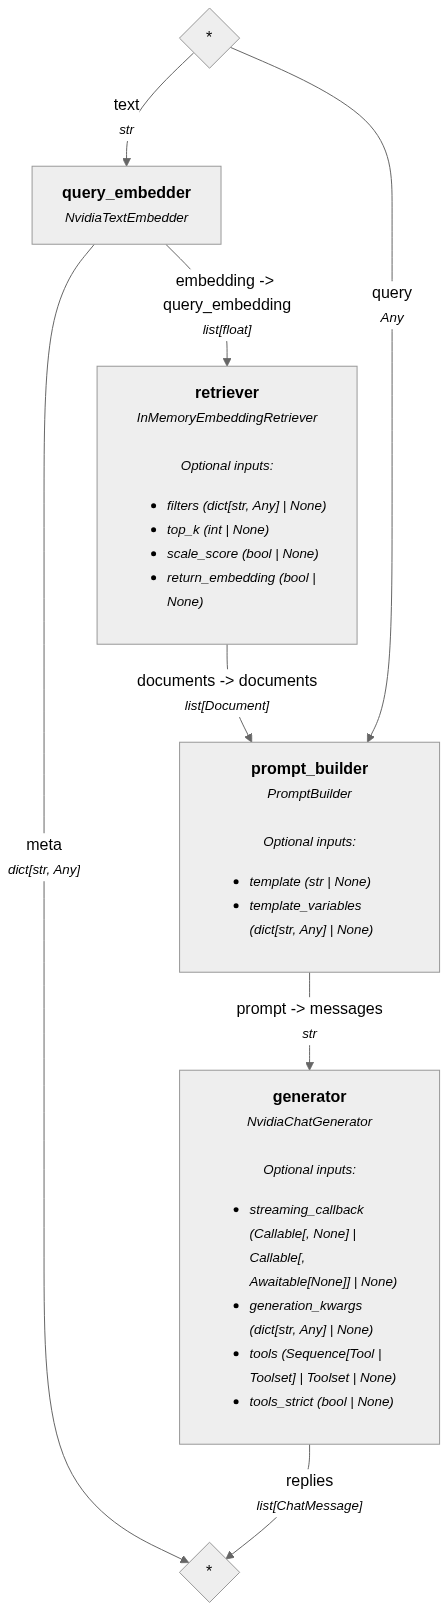

In [19]:
from haystack.components.routers import ConditionalRouter

rag_prompt = """
Answer the following query give the documents.
If the answer is not contained in the documents, reply with 'no_answer'
Query: {{query}}
Documents:
{% for doc in documents %}
  {{ doc.content }}
{% endfor %}
"""

# modules needed for generation
query_embedder = NvidiaTextEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
retriever = InMemoryEmbeddingRetriever(document_store=doc_store)
prompt_builder = PromptBuilder(template=rag_prompt)
generator = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning",api_key=NVIDIA_API_KEY)

rag = Pipeline()
rag.add_component("query_embedder", query_embedder)
rag.add_component("retriever", retriever)
rag.add_component("prompt_builder", prompt_builder)
rag.add_component("generator", generator)

rag.connect("query_embedder.embedding", "retriever.query_embedding")
rag.connect("retriever.documents", "prompt_builder.documents")
rag.connect("prompt_builder", "generator")

rag.show()

In [20]:
# example to present no answer from LM
query = "What is Higgs Boson?"

rag.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 9,
    'total_tokens': 9}}},
 'generator': {'replies': [ChatMessage(_role=<ChatRole.ASSISTANT: 'assistant'>, _content=[TextContent(text='no_answer')], _name=None, _meta={'model': 'nvidia/nemotron-3-nano-omni-30b-a3b-reasoning', 'index': 0, 'finish_reason': 'stop', 'usage': {'completion_tokens': 52, 'prompt_tokens': 91, 'total_tokens': 143, 'completion_tokens_details': None, 'prompt_tokens_details': None}})]}}

In [21]:
# conditional rules

routes = [
    {
        "condition": "{{'no_answer' in replies[0]|lower}}",
        "output": "{{query}}",
        "output_name": "go_to_websearch",
        "output_type": str
    },
    {
        "condition": "{{'no_asnwer' not in replies[0]|lower}}",
        "output": "{{replies[0]}}",
        "output_name": "answer",
        "output_type": str
    }
]

router = ConditionalRouter(routes=routes)
print(router.run(replies=["Bangalore"], query="Where is IISc?"))
print(router.run(replies=['no_answer'], query="Where is IISc?"))

{'answer': 'Bangalore'}
{'go_to_websearch': 'Where is IISc?'}


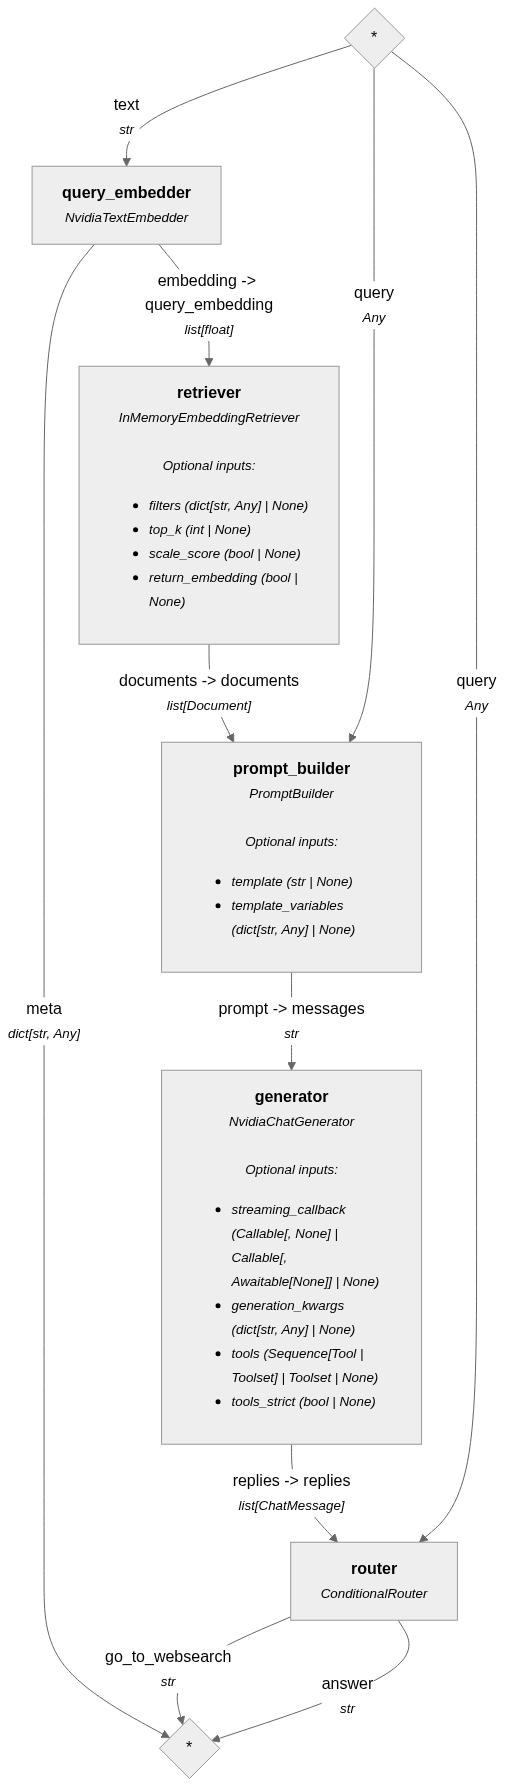

In [22]:
rag.add_component("router", router)
rag.connect("generator.replies", "router.replies")

rag.show()

In [23]:
query = "Where is IISc?"
rag.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query},
        "router": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 7,
    'total_tokens': 7}}},
 'router': {'go_to_websearch': 'Where is IISc?'}}

In [24]:
query = "What is universal gravitational law?"
rag.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query},
        "router": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 8,
    'total_tokens': 8}}},
 'router': {'answer': 'ChatMessage(_role=<ChatRole.ASSISTANT: \'assistant\'>, _content=[TextContent(text="Newton\'s law of universal gravitation states that every particle in the universe attracts every other particle with a force proportional to the product of their masses and inversely proportional to the square of the distance between them.")], _name=None, _meta={\'model\': \'nvidia/nemotron-3-nano-omni-30b-a3b-reasoning\', \'index\': 0, \'finish_reason\': \'stop\', \'usage\': {\'completion_tokens\': 150, \'prompt_tokens\': 90, \'total_tokens\': 240, \'completion_tokens_details\': None, \'prompt_tokens_details\': None}})'}}

In [ ]:
# create a websearch branch

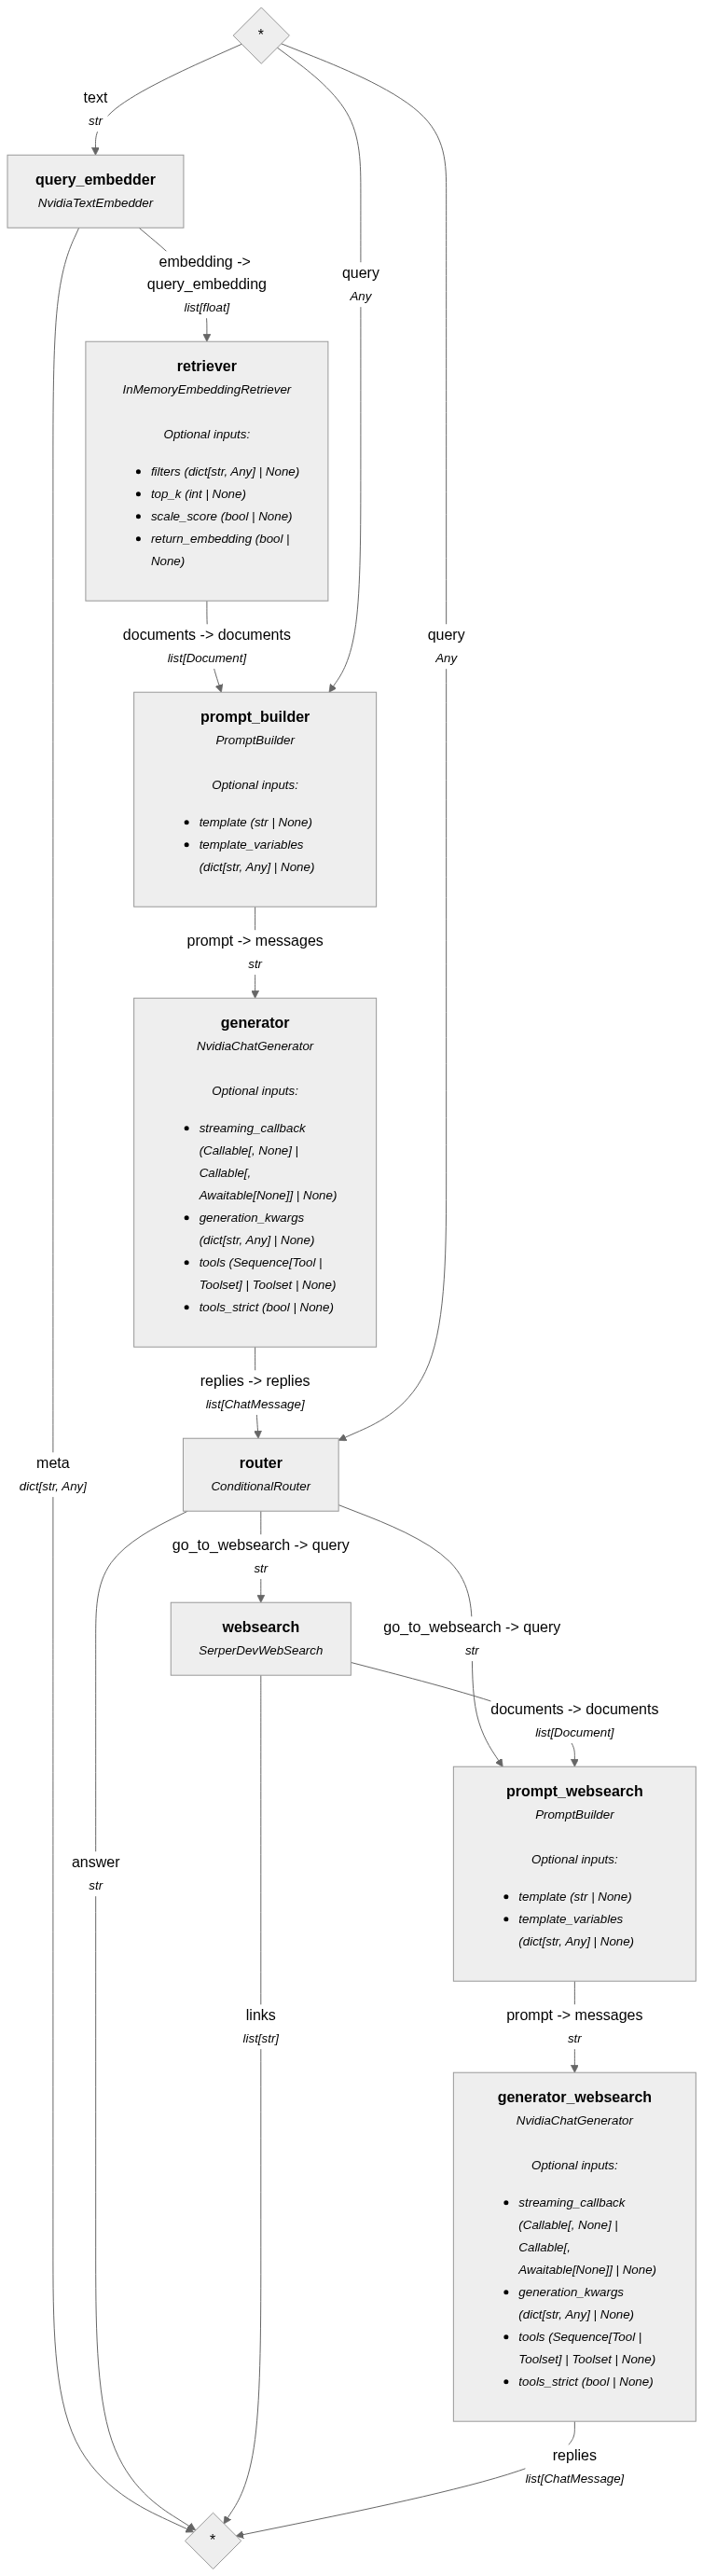

In [25]:
from haystack_integrations.components.websearch.serperdev import SerperDevWebSearch

websearch_prompt = """
Answer the following query given the documents retrieved from the web.
Your answer should indicate that your answer was generated from websearch.
You can also reference the URLs that answer was generated from

Query: {{query}}
Documents:
{% for doc in documents %}
  {{ doc.content }}
{% endfor %}
"""

# modules needed for generation
query_embedder = NvidiaTextEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
retriever = InMemoryEmbeddingRetriever(document_store=doc_store)
prompt_builder = PromptBuilder(template=rag_prompt)
generator = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning",api_key=NVIDIA_API_KEY)
router = ConditionalRouter(routes=routes)
websearch = SerperDevWebSearch(api_key=SERPER_API_KEY)
prompt_websearch = PromptBuilder(template=websearch_prompt)
generator_websearch = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning",api_key=NVIDIA_API_KEY)

rag_websearch = Pipeline()
rag_websearch.add_component("query_embedder", query_embedder)
rag_websearch.add_component("retriever", retriever)
rag_websearch.add_component("prompt_builder", prompt_builder)
rag_websearch.add_component("generator", generator)
rag_websearch.add_component("router", router)
rag_websearch.add_component("websearch", websearch)
rag_websearch.add_component("prompt_websearch", prompt_websearch)
rag_websearch.add_component("generator_websearch", generator_websearch)

rag_websearch.connect("query_embedder.embedding", "retriever.query_embedding")
rag_websearch.connect("retriever.documents", "prompt_builder.documents")
rag_websearch.connect("prompt_builder", "generator")
rag_websearch.connect("generator.replies", "router.replies")
rag_websearch.connect("router.go_to_websearch", "websearch.query")
rag_websearch.connect("router.go_to_websearch", "prompt_websearch.query")
rag_websearch.connect("websearch.documents", "prompt_websearch.documents")
rag_websearch.connect("prompt_websearch", "generator_websearch")

rag_websearch.show()

In [26]:
query = "What is universal gravitational law?"
rag_websearch.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query},
        "router": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 8,
    'total_tokens': 8}}},
 'router': {'answer': 'ChatMessage(_role=<ChatRole.ASSISTANT: \'assistant\'>, _content=[TextContent(text="Newton\'s law of universal gravitation states that every particle in the universe attracts every other particle with a force proportional to their masses and inversely proportional to the square of the distance between them.")], _name=None, _meta={\'model\': \'nvidia/nemotron-3-nano-omni-30b-a3b-reasoning\', \'index\': 0, \'finish_reason\': \'stop\', \'usage\': {\'completion_tokens\': 158, \'prompt_tokens\': 90, \'total_tokens\': 248, \'completion_tokens_details\': None, \'prompt_tokens_details\': None}})'}}

In [27]:
query = "Where is IISc?"
rag_websearch.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query},
        "router": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 7,
    'total_tokens': 7}}},
 'websearch': {'links': ['https://en.wikipedia.org/wiki/Indian_Institute_of_Science',
   'https://www.iisc.ac.in/locations/iisc-main-campus/',
   'https://www.iisc.ac.in/',
   'https://www.quora.com/What-is-the-reputation-of-IISc-Indian-institute-of-Science-Brand-outside-India-1',
   'https://www.iisc.ac.in/about/foreword-from-the-director/',
   'https://www.facebook.com/groups/1528556590661443/posts/2881537455363343/',
   'https://testbook.com/question-answer/where-is-the-indian-institute-of-science-iisc-lo--65fabb1495fb42cacb345842',
   'https://www.iisc.ac.in/about/general-information/how-to-reach-iisc/',
   'https://www.instagram.com/reel/DPFw-kOknAt/',
   'https://www.gktoday.in/indian-institute-of-science-iisc/']},
 'generator_websearch': {'replies': [ChatMessage(_role=<ChatRole.ASSISTANT: 'assistant'>, _content=[TextContent(text='IISc is located in Bengaluru, Karnataka, India.  \n\n**Sources**  

In [28]:
query = "Reshare the previous queries answer"
rag_websearch.run(
    {
        "query_embedder": {"text": query},
        "retriever": {"top_k": 1},
        "prompt_builder": {"query": query},
        "router": {"query": query}
    }
)

{'query_embedder': {'meta': {'usage': {'prompt_tokens': 9,
    'total_tokens': 9}}},
 'websearch': {'links': ['https://www.sciencedirect.com/topics/computer-science/answering-query',
   'https://www.honeycomb.io/blog/sharing-query-history',
   'https://gofishdigital.com/blog/conversational-search-at-google/',
   'https://docs.oracle.com/en/industries/life-sciences/clinical-one/site-information/answer-query.html',
   'https://stackoverflow.com/questions/650238/how-to-show-the-last-queries-executed-on-mysql',
   'https://learn.microsoft.com/en-us/answers/questions/1134833/history-of-queries-ran-yesterday-from-a-specific-d',
   'https://arxiv.org/html/2403.19302v2',
   'https://www.reddit.com/r/SQLServer/comments/13q9as0/is_there_a_way_to_view_your_query_history/',
   'https://academy.harvey.ai/find-and-reuse-prior-work-with-history',
   'https://support.quest.com/toad-for-oracle/kb/4295212/how-to-re-open-or-show-previously-ran-sql-query-statements-after-closing-toad-for-oracle']},
 'gene

In [ ]:
# persist chat history

In [30]:
from haystack.dataclasses import ChatMessage

# enhancement in routes to return ChatMessage format in case of RAG response instead of string
routes = [
    {
        "condition": "{{'no_answer' in replies[0].text|lower}}",
        "output": "query",
        "output_name": "go_to_websearch",
        "output_type": str,
        "output_passthrough": True
    },
    {
        "condition": "{{'no_asnwer' not in replies[0].text|lower}}",
        "output": "replies",
        "output_name": "answer",
        "output_type": list[ChatMessage],
        "output_passthrough": True
    }
]

router = ConditionalRouter(routes=routes)
print(router.run(replies=["Bangalore"], query="Where is IISc?"))
print(router.run(replies=["no_answer"], query="Where is IISC?"))

{'answer': ['Bangalore']}
{'answer': ['no_answer']}


In [31]:
from haystack.components.builders import ChatPromptBuilder
from haystack_integrations.components.generators.nvidia import NvidiaChatGenerator
from haystack_integrations.components.embedders.nvidia import NvidiaTextEmbedder
from haystack.components.retrievers.in_memory import InMemoryEmbeddingRetriever
from haystack.components.routers import ConditionalRouter
from haystack_integrations.components.websearch.serperdev import SerperDevWebSearch
from haystack.components.builders import PromptBuilder
from haystack import Pipeline

rewrite_prompt = [
    ChatMessage.from_system(
        "Given the following conversation history and follow-up question, "
        "rephrase the follow-up question to be a standalone question."
        "If no conversation history exists, output the follow up question exactly as is"
    ),
    ChatMessage.from_user(
        "History: {% for msg in history %}{{msg.role}}: {{msg.text}}\n{% endfor %}"
        "Follow-up: {{query}}"
    )
]

rag_prompt = [
    ChatMessage.from_system(
        """Answer the following query given the documents.
        If the answer is not contained in the documents, reply with 'no_answer'

        Documents:
        {% for doc in documents %}
          {{ doc.content }}
        {% endfor %}
        """
    ),
    ChatMessage.from_user(
        """Conversation History:\n
        {% for msg in history %}
        {{ msg.role }}: {{ msg.text }}
        {% endfor %}
        Query: {{query}}
        """
    )
]

websearch_prompt = [
    ChatMessage.from_system(
        """
        Answer the following query given the documents retrieved from the web.
        Your answer should indicate that your answer was generated from websearch.
        You can also reference the URLs that answer was generated from

        Query: {{query}}
        Documents:
        {% for doc in documents %}
          {{ doc.content }}
        {% endfor %}
        """
    )
]

# modules needed for generation
query_rewriter_prompt = ChatPromptBuilder(template=rewrite_prompt)
query_rewriter = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning", api_key=NVIDIA_API_KEY)
query_embedder = NvidiaTextEmbedder(model="nvidia/nemotron-3-embed-1b", api_key=NVIDIA_API_KEY)
retriever = InMemoryEmbeddingRetriever(document_store=doc_store)
prompt_builder = ChatPromptBuilder(template=rag_prompt)
generator = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning", api_key=NVIDIA_API_KEY)
router = ConditionalRouter(routes=routes)
websearch = SerperDevWebSearch(api_key=SERPER_API_KEY)
prompt_websearch = ChatPromptBuilder(template=websearch_prompt)
generator_websearch = NvidiaChatGenerator(model="nvidia/nemotron-3-nano-omni-30b-a3b-reasoning", api_key=NVIDIA_API_KEY)

rag_history = Pipeline()
rag_history.add_component("query_rewriter_prompt", query_rewriter_prompt)
rag_history.add_component("query_rewriter", query_rewriter)
rag_history.add_component("query_embedder", query_embedder)
rag_history.add_component("retriever", retriever)
rag_history.add_component("prompt_builder", prompt_builder)
rag_history.add_component("generator", generator)
rag_history.add_component("router", router)
rag_history.add_component("websearch", websearch)
rag_history.add_component("prompt_websearch", prompt_websearch)
rag_history.add_component("generator_websearch", generator_websearch)

🚅 Components
  - query_rewriter_prompt: ChatPromptBuilder
  - query_rewriter: NvidiaChatGenerator
  - query_embedder: NvidiaTextEmbedder
  - retriever: InMemoryEmbeddingRetriever
  - prompt_builder: ChatPromptBuilder
  - generator: NvidiaChatGenerator
  - router: ConditionalRouter
  - websearch: SerperDevWebSearch
  - prompt_websearch: ChatPromptBuilder
  - generator_websearch: NvidiaChatGenerator
🛤️ Connections

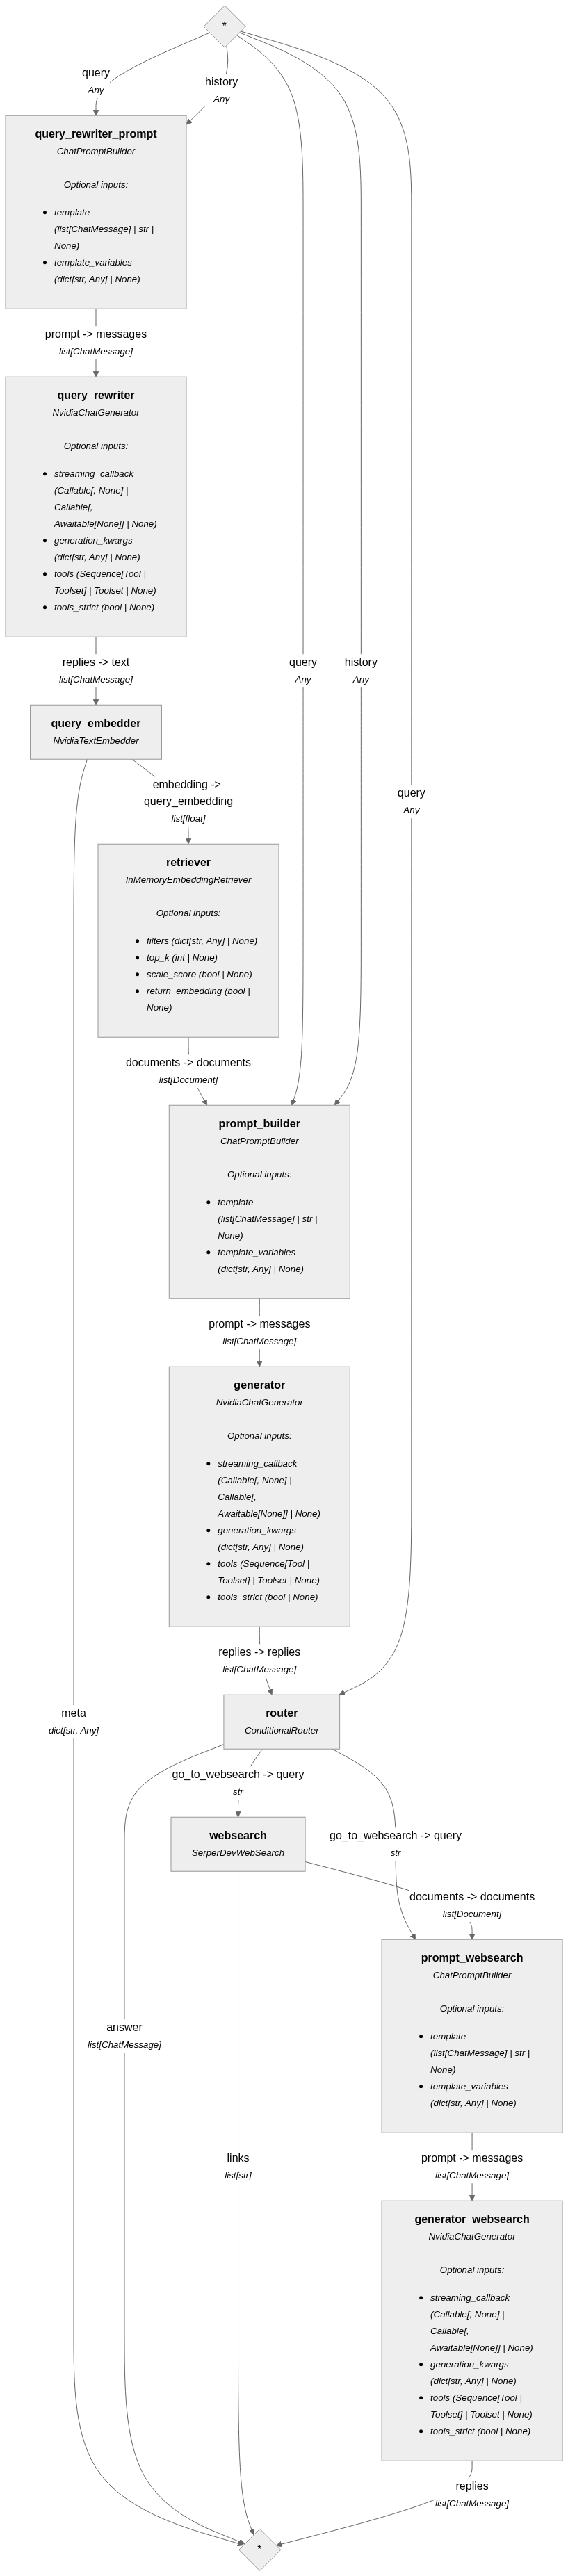

In [32]:
rag_history.connect("query_rewriter_prompt", "query_rewriter.messages")
rag_history.connect("query_rewriter.replies", "query_embedder.text")
rag_history.connect("query_embedder.embedding", "retriever.query_embedding")
rag_history.connect("retriever.documents", "prompt_builder.documents")
rag_history.connect("prompt_builder", "generator")
rag_history.connect("generator.replies", "router.replies")
rag_history.connect("router.go_to_websearch", "websearch.query")
rag_history.connect("router.go_to_websearch", "prompt_websearch.query")
rag_history.connect("websearch.documents", "prompt_websearch.documents")
rag_history.connect("prompt_websearch", "generator_websearch")

rag_history.show()

In [33]:
chat_history = []

def chat_with_rag(user_input: str, history):

  # Ensure we append ChatMessage objects to chat history
  chat_history.append(ChatMessage.from_user(user_input))

  results = rag_history.run(
      {
          "query_rewriter_prompt": {"history": chat_history, "query": user_input},
          "prompt_builder": {"history": chat_history, "query": user_input},
          "router": {"query": user_input}
      }
  )

  # The router might return the direct answer if found in document store,
  # or the pipeline falls back to generator_websearch if it went to websearch.
  if "generator_websearch" in results and "replies" in results["generator_websearch"]:
      ai_response = results["generator_websearch"]["replies"][0].text
  elif "router" in results and "answer" in results["router"]:
      # The router returns the raw ChatMessage string representation based on the route definition
      # Let's extract the response object or content
      ai_response = results["router"]["answer"][0].text
  else:
      # Fallback if structure differs
      ai_response = "No answer found."


  if isinstance(ai_response, ChatMessage):
      chat_history.append(ai_response)
      response_text = ai_response.text
  else:
      # If it is a string representation of ChatMessage, or raw string
      chat_history.append(ChatMessage.from_assistant(str(ai_response)))
      response_text = str(ai_response)

  return response_text

In [34]:
print(chat_with_rag("Give me the definition of AI in one sentence", ""))

AI is the capability of computational systems to perform tasks that normally require human intelligence, such as learning, reasoning, and problem solving【source】.


In [35]:
print(chat_with_rag("What is universal gravitational law?", ""))

Newton's law of universal gravitation states that every particle in the universe attracts every other particle with a force proportional to the product of their masses and inversely proportional to the square of the distance between them.


In [37]:
print(chat_with_rag("Reshare the previous queries answer", ""))

Newton's law of universal gravitation states that every particle in the universe attracts every other particle with a force proportional to the product of their masses and inversely proportional to the square of the distance between them.


In [ ]:
# retains previous discussions now
# for demo purposes we can do quick UI with gradio

In [38]:
import gradio as gr

demo = gr.ChatInterface(
    fn=chat_with_rag,
    examples=[
        "What is universal gravitational law?",
        "Give me the definition of AI in one sentence",
        "What's the weather in Bengaluru today?",
        "What is Higgs Boson?"
    ],
    title="Conversational RAG Search",
    description="I'm a helpful assistant. Ask me anything!"
)

demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7b4cede30d55986a59.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7b4cede30d55986a59.gradio.live
